In [1]:
from utils230405 import *

In [2]:
mesh_database_path = r"../99_broccoli_models"

mesh_db = {}
for file in os.listdir(mesh_database_path):
    if ".obj" in file:
        mesh_db[file[:-4]] = os.path.join(mesh_database_path, file)

In [3]:
# load the failed brocooli
bro_id = '2-31'
mesh = o3d.io.read_triangle_mesh(mesh_db[bro_id])
def_test_pcd = mesh2pcd(mesh)

The old version results

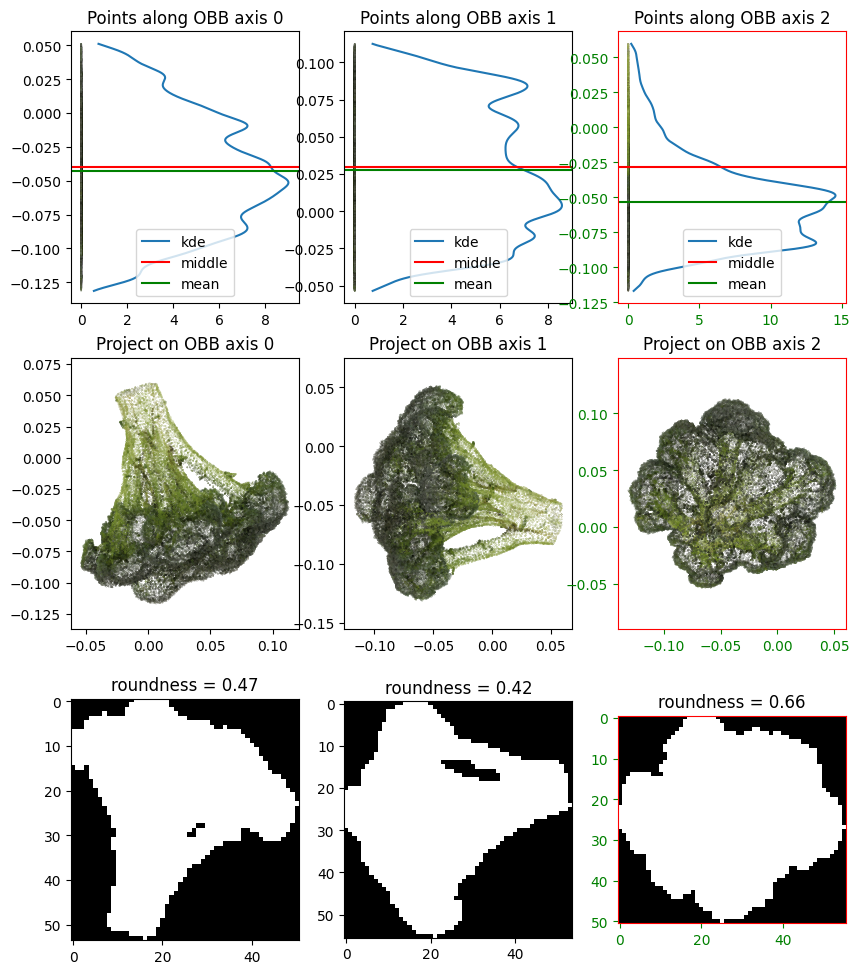

<Figure size 640x480 with 0 Axes>

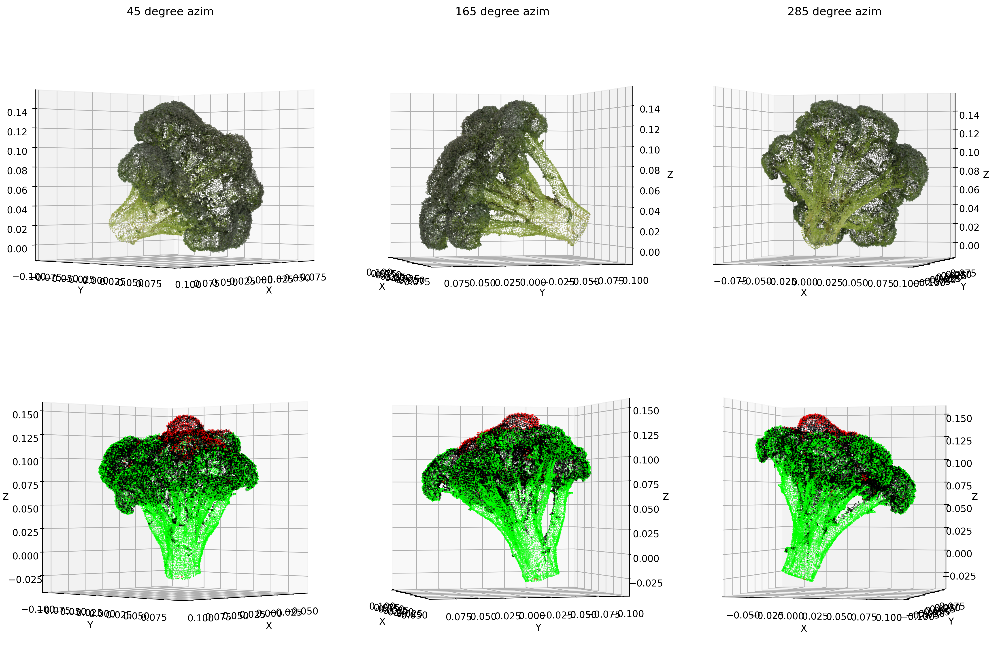

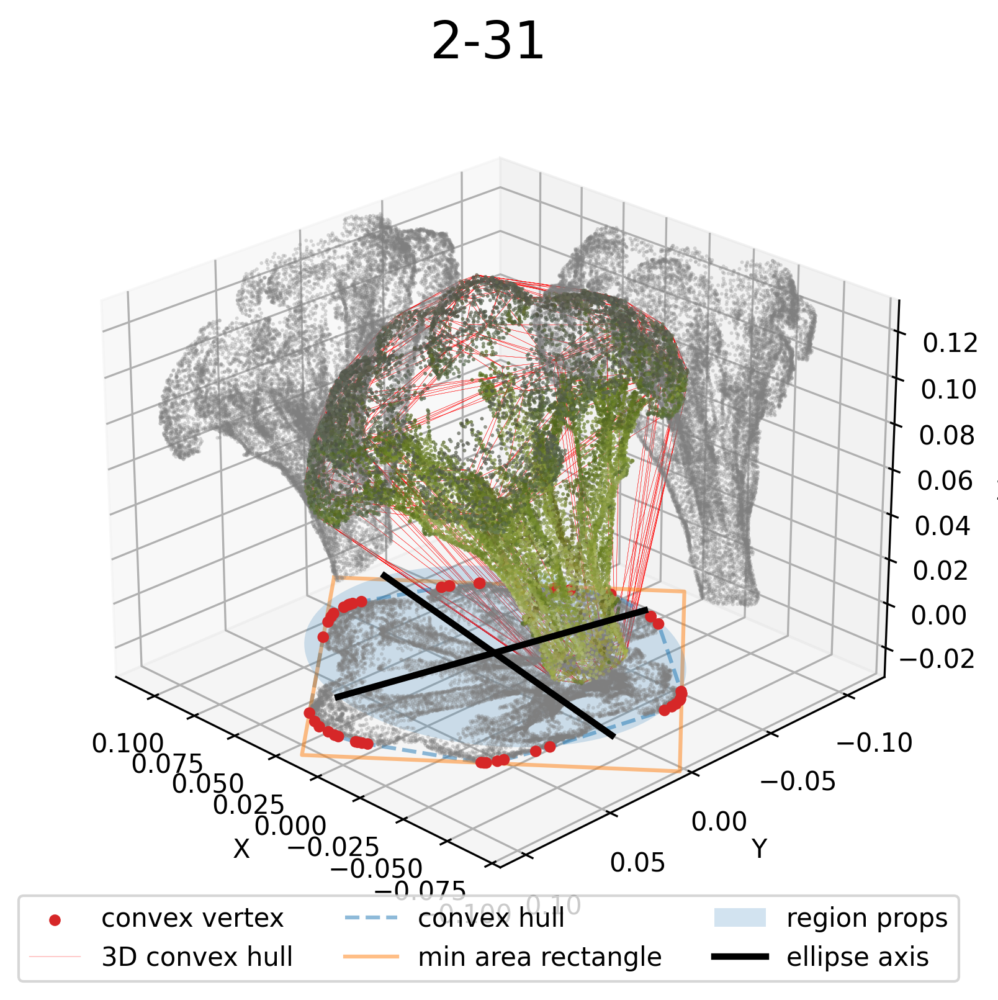

In [4]:
crown_pcd, crown_colored_pcd, crown_points_index = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, show=True)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, show=True)#f"out/v220405/{broccoli_id}_rot_seg.png")

crown_traits = Broccoli(rotated_pcd.select_by_index(crown_points_index), bro_id)
draw_3d_results(crown_traits, bro_id, down_voxel_size=0.001, show=True)

In [6]:
def segment_crown_debug(head_pcd, denoise_count=20, denoise_radius=0.01, show_log=False):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # 把点云投影到最长轴上
    # pcd_on_z -> (x, y, z) 3D
    pcd_on_z = points_on_vector(np.asarray(head_pcd.points), obb.R[:,main_idx])
    # project 3D line to 1D
    pcd_on_z_unit = (pcd_on_z / obb.R[:,main_idx])[:,0]

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
    kmeans.fit(rgb)

    return kmeans.labels_ == 0, kmeans.labels_ == 1

In [8]:
l0, l1 = segment_crown_debug(def_test_pcd, 10, 0.005, show_log=False)
l0

array([False, False, False, ...,  True,  True,  True])

In [9]:
pcd_class0 = def_test_pcd.select_by_index(np.where(l0)[0])
pcd_class1 = def_test_pcd.select_by_index(np.where(l1)[0])

In [10]:
o3d.visualization.draw_geometries([pcd_class1])

In [12]:
rgb_class0 = np.asarray(pcd_class0.colors)
rgb_class1 = np.asarray(pcd_class1.colors)

In [13]:
rgb_class0.mean(axis=0)

array([0.41156585, 0.46218038, 0.24656579])

In [14]:
pcd_class0.paint_uniform_color(rgb_class0.mean(axis=0))
pcd_class1.paint_uniform_color(rgb_class1.mean(axis=0))

PointCloud with 37860 points.

In [15]:
o3d.visualization.draw_geometries([pcd_class0, pcd_class1])

In [16]:
from skimage.color import rgb2hsv

In [17]:
hsv_class0 = rgb2hsv(rgb_class0.mean(axis=0))
hsv_class1 = rgb2hsv(rgb_class1.mean(axis=0))

In [18]:
hsv_class0, hsv_class1

(array([0.2057909 , 0.46651611, 0.46218038]),
 array([0.21767829, 0.42222336, 0.2348048 ]))

In [19]:
def segment_crown(head_pcd, denoise_count=20, denoise_radius=0.01, show_log=False):
    # 计算定向边界框
    obb = head_pcd.get_oriented_bounding_box()
    # find the maximum edge and its vector:
    main_idx = np.argmax(obb.extent)

    # use Kmeans to classify points to 2 class by color
    rgb = np.asarray(head_pcd.colors)
    kmeans = KMeans(n_clusters=2, random_state=0, n_init=10)
    kmeans.fit(rgb)

    pcd_class0 = def_test_pcd.select_by_index(
        np.where(kmeans.labels_ == 0)[0]
    )
    pcd_class1 = def_test_pcd.select_by_index(
        np.where(kmeans.labels_ == 1)[0]
    )

    rgb_class0 = np.asarray(pcd_class0.colors)
    rgb_class1 = np.asarray(pcd_class1.colors)

    hsv_class0 = rgb2hsv(rgb_class0.mean(axis=0))
    hsv_class1 = rgb2hsv(rgb_class1.mean(axis=0))

    if hsv_class0[2] < hsv_class1[2]:
        crown_bool_idx = kmeans.labels_ == 0
    else:
        crown_bool_idx = kmeans.labels_ == 1

    crown_int_idx = np.where(crown_bool_idx)[0]

    crown_pcd = head_pcd.select_by_index(crown_int_idx)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_radius_outlier(denoise_count, denoise_radius)
    # crown_pcd_denoised, keeped_int_idx = crown_pcd.remove_statistical_outlier(denoise_count, denoise_radius)
    crown_pcd_denoised, keeped_int_idx = remove_dbscan_outlier(crown_pcd, denoise_count, denoise_radius, show_log)
    crown_denoised_int_idx = crown_int_idx[keeped_int_idx]

    ## create a results pcd, 
    labeled_pcd = o3d.geometry.PointCloud()

    ### black for stem
    label_rgb = np.zeros((len(head_pcd.points), 3))
    ### red for denoised
    label_rgb[crown_bool_idx, :] = np.array([1,0,0])
    ### green for crown
    label_rgb[crown_denoised_int_idx,:] = np.array([0,1,0])

    labeled_pcd.points = o3d.utility.Vector3dVector(head_pcd.points)
    labeled_pcd.colors = o3d.utility.Vector3dVector(label_rgb)

    #################
    ## draw figures
    #################
    if show_log:
        kde0 = stats.gaussian_kde(z0)
        xx0 = np.linspace(pmin, pmax, 1000)
        yy0 = kde0(xx0)

        kde1 = stats.gaussian_kde(z1)
        xx1 = np.linspace(pmin, pmax, 1000)
        yy1 = kde1(xx1)

        fig, ax = plt.subplots(1,1)
        ax.plot(xx0, yy0,color='b', label='z0')
        ax.plot(xx1, yy1,color='g', label='z1')

        ax.axvline(x=pmid, color='r', label="middle")

        ax.axvline(x=z0_mean, color='b', label="z0mean")
        ax.axvline(x=z1_mean, color='g',label="z1mean")

        plt.legend()
        plt.show()

    return crown_pcd_denoised, labeled_pcd, crown_denoised_int_idx

In [22]:
bro_id = '2-31'
mesh = o3d.io.read_triangle_mesh(mesh_db[bro_id])
def_test_pcd = mesh2pcd(mesh)

crown_pcd, crown_colored_pcd, crown_points_index = segment_crown(def_test_pcd, 10, 0.005, show_log=False)

<Figure size 640x480 with 0 Axes>

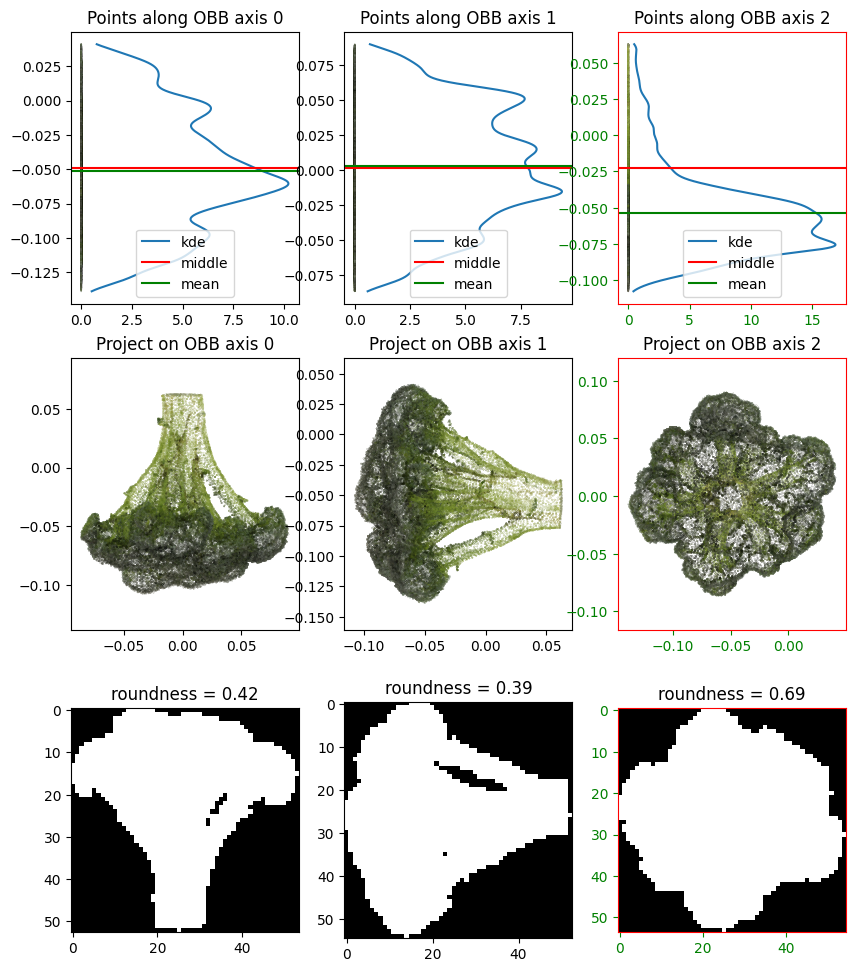

<Figure size 640x480 with 0 Axes>

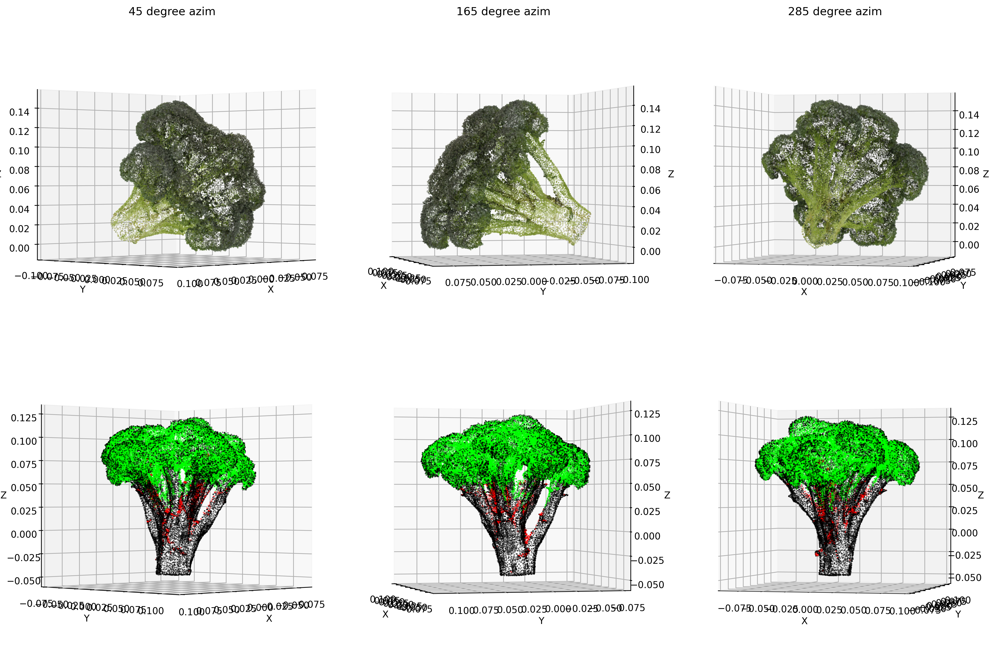

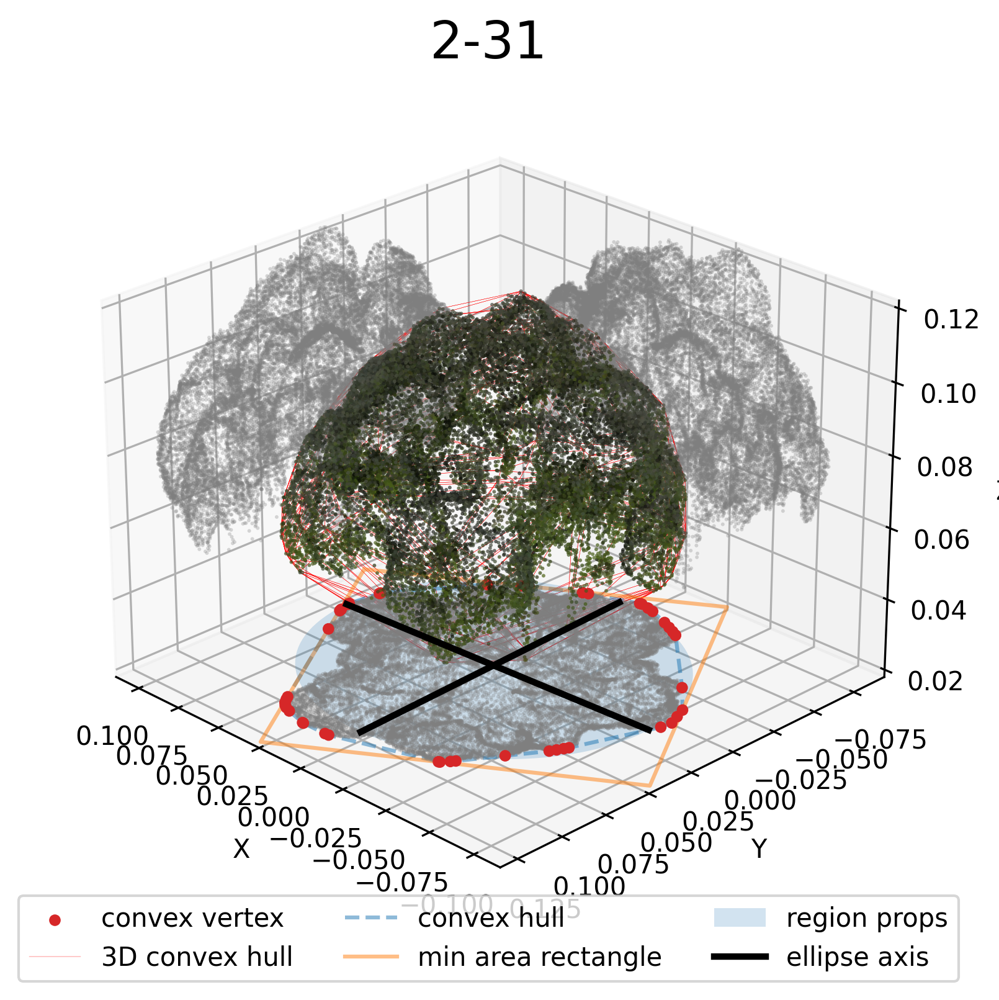

In [23]:
rotated_pcd, R = rotate_to_z(crown_pcd, def_test_pcd, show=True)

# draw figures
xyz_o = np.asarray(def_test_pcd.points)
rgb_o = np.asarray(def_test_pcd.colors)

xyz_r = np.asarray(rotated_pcd.points)
rgb_r = np.asarray(crown_colored_pcd.colors)

draw_rotated(xyz_o, rgb_o, xyz_r, rgb_r, show=True)#f"out/v220405/{broccoli_id}_rot_seg.png")

crown_traits = Broccoli(rotated_pcd.select_by_index(crown_points_index), bro_id)
draw_3d_results(crown_traits, bro_id, down_voxel_size=0.001, show=True)